# TREM2 — which cells express it? (quick look)
Single cell (`annotation_v4.h5ad`): % of cells with >= 1 UMI and pooled CPM per population, share of all TREM2 UMI, consistency across mice. Template: `marco_expression_sc.py`. Gene is a parameter.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, h5py, anndata as ad, scipy.sparse as sp
import matplotlib.pyplot as plt
GENE = "Trem2"
PROJ = next(p for p in [Path("/Users/janzules/Roselab/Spatial/CAR_T"), Path("/coh_labs/yunroseli/Jona/CAR-T")] if p.exists())
SC = PROJ/"data/sc-reference/annotation_v4.h5ad"
OUT = PROJ/"results/SpecificGenes/trem2"; OUT.mkdir(parents=True, exist_ok=True)
with h5py.File(SC,"r") as f:
    obs = ad.io.read_elem(f["obs"]); var = ad.io.read_elem(f["var"]); C = sp.csr_matrix(ad.io.read_elem(f["layers/counts"]))
genes = pd.Index(var.index.astype(str)); assert GENE in genes
d = pd.DataFrame({"ct2":obs.cell_type_lvl2.astype(str).values,"ct3":obs.cell_type_lvl3.astype(str).values,"sample":obs.file_name.astype(str).values,
                  "n":np.asarray(C.sum(1)).ravel(),"x":C[:,genes.get_loc(GENE)].toarray().ravel()},index=obs.index)
d["mouse"]=d["sample"].str.replace(r"_Tu\d_","_",regex=True); d["pos"]=d.x>0
print(f"{GENE}: {int(d.pos.sum()):,} of {len(d):,} cells ({100*d.pos.mean():.1f}%), {int(d.x.sum()):,} UMI")
def tab(key):
    g=d.groupby(key); t=pd.DataFrame({"cells":g.size(),"pct_pos":100*g.pos.mean(),"cpm":1e6*g.x.sum()/g.n.sum(),"share_of_UMI_pct":100*g.x.sum()/d.x.sum()})
    t["mice_ge5pct"]=d.groupby([key,"mouse"]).pos.mean().gt(0.05).groupby(level=0).sum()
    return t.sort_values("pct_pos",ascending=False).round(2)
T2, T3 = tab("ct2"), tab("ct3"); T2.to_csv(OUT/"trem2_by_lvl2.csv"); T3.to_csv(OUT/"trem2_by_lvl3.csv")
print("\nBY LVL2:"); print(T2.to_string()); print("\nBY LVL3 (top 15):"); print(T3.head(15).to_string())

Trem2: 31,277 of 93,548 cells (33.4%), 89,353 UMI

BY LVL2:
                   cells  pct_pos     cpm  share_of_UMI_pct  mice_ge5pct
ct2                                                                     
M2_like_Mac        23538    72.92  244.50             72.67           15
Intermediate_Mac    9221    42.39   79.28              8.56           15
M1_like_Mac        15716    29.19   57.71              9.37           14
Classical_Mono     25955    18.83   38.62              8.42           14
Nonclassical_Mono   4570    10.90   18.00              0.67           13
CD4_T                 85     3.53    4.09              0.00            3
cDC                 1381     3.26    4.96              0.07            3
Erythrocyte           95     3.16    6.14              0.00            2
Endothelial          296     2.70    3.64              0.01            2
Fibroblast           288     2.08    1.88              0.01            2
B                     53     1.89    4.68              0.00     

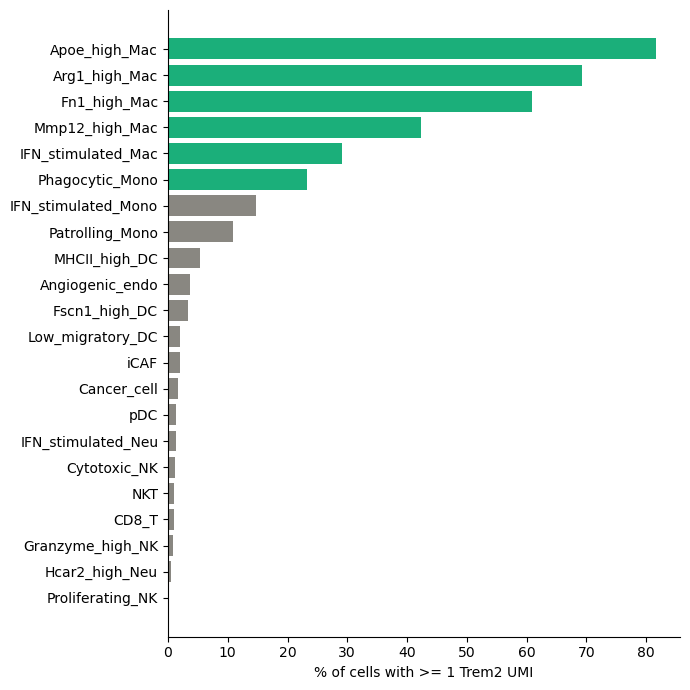

SUMMARY highest lvl2: M2_like_Mac 73% (73% of UMI); Intermediate_Mac 42% (9% of UMI); M1_like_Mac 29% (9% of UMI)
largest contributors to all TREM2 UMI: M2_like_Mac 73%; M1_like_Mac 9%; Intermediate_Mac 9%


In [2]:
t=T3[T3.cells>=100].sort_values("pct_pos"); fig,ax=plt.subplots(figsize=(7,7))
ax.barh(t.index,t.pct_pos,color=["#1baf7a" if v>=20 else "#898781" for v in t.pct_pos]); ax.set_xlabel(f"% of cells with >= 1 {GENE} UMI")
for s in ("top","right"): ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(OUT/"trem2_by_celltype.png",dpi=200); plt.show()
print("SUMMARY highest lvl2:", "; ".join(f"{i} {r.pct_pos:.0f}% ({r.share_of_UMI_pct:.0f}% of UMI)" for i,r in T2.head(3).iterrows()))
print("largest contributors to all TREM2 UMI:", "; ".join(f"{i} {r.share_of_UMI_pct:.0f}%" for i,r in T2.sort_values("share_of_UMI_pct",ascending=False).head(3).iterrows()))